# What Drives Launch Success? A Data-Driven Study Using Linear and Multiple Regression

**Question:** which launch factors (brand familiarity, launch discount, advertising spend, social media mentions) best predict a product's launch success probability across 1,500 product launches?

MSc Business Analytics coursework, University of Greenwich (2025–26)

Module: Advanced Analytics: Statistics and Machine Learning (COMP1942), Statistical Analysis Report

## Setting Up Libraries

In [1]:
# Importing all the necessary libraries
import os                                               # For creating the figures folder
import pandas as pd                                     # For data manipulation and analysis
import numpy as np                                      # For numerical operations
import matplotlib.pyplot as plt                         # For creating static, interactive, and animated visualizations
import statsmodels.api as sm                            # For estimating different statistical models
import seaborn as sns                                   # For statistical data visualization
from sklearn.preprocessing import MinMaxScaler          # For normalizing numerical features to a 0–1 range
from scipy import stats                                 # For statistical functions
from scipy.stats import pearsonr                        # For calculating Pearson correlation coefficient
from statsmodels.stats.stattools import durbin_watson   # For checking autocorrelation in residuals
from statsmodels.formula.api import ols                 # For Ordinary Least Squares (OLS) using formula strings

In [2]:
# Loading the dataset
df = pd.read_excel("../data/Dataset.xlsx")

# Folder for the key charts used in the README
os.makedirs("../figures", exist_ok=True)

In [3]:
# Checking the number of rows and columns
display(df.shape)

# Checking the data types of each column
print(df.dtypes)

# Checking data types, non-null counts, and memory usage
display(df.info())

# Summary statistics for numerical variables
display(df.describe())

(1500, 17)

product_id                   int64
units_sold_first_30d         int64
launch_discount_pct        float64
ad_spend_usd                 int64
store_region_index           int64
product_price_usd          float64
shelf_space_sqft           float64
brand_familiarity_score    float64
social_media_mentions        int64
product_category_index       int64
competitor_count_nearby      int64
weekday_launch_flag          int64
season_index                 int64
internal_reference_code      int64
revenue_first_30d_usd      float64
success_probability        float64
is_successful                int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   product_id               1500 non-null   int64  
 1   units_sold_first_30d     1500 non-null   int64  
 2   launch_discount_pct      1500 non-null   float64
 3   ad_spend_usd        

None

,product_id,units_sold_first_30d,launch_discount_pct,ad_spend_usd,store_region_index,product_price_usd,shelf_space_sqft,brand_familiarity_score,social_media_mentions,product_category_index,competitor_count_nearby,weekday_launch_flag,season_index,internal_reference_code,revenue_first_30d_usd,success_probability,is_successful
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,55935.380000,200.127333,19.898667,5011.774667,3.016000,29.832553,11.832200,0.498627,50.359333,3.038000,2.913333,0.514667,2.500667,548060.797333,5976.649993,0.326601,0.215333
std,25834.666138,14.238666,11.372615,1504.915671,1.433334,10.062563,4.055265,0.286350,7.375713,1.420059,1.685937,0.499952,1.114822,258706.394582,2342.248798,0.221370,0.411190
min,10034.000000,152.000000,0.000000,1000.000000,1.000000,5.000000,1.000000,0.000000,25.000000,1.000000,0.000000,0.000000,1.000000,100003.000000,0.000000,0.000000,0.000000
25%,34257.750000,190.000000,10.175000,3976.500000,2.000000,22.880000,9.100000,0.250000,45.000000,2.000000,2.000000,0.000000,1.000000,329788.000000,4398.405000,0.176750,0.000000
50%,55913.500000,200.000000,19.950000,5061.000000,3.000000,30.025000,11.800000,0.500000,50.000000,3.000000,3.000000,1.000000,3.000000,536993.500000,5967.640000,0.299000,0.000000
75%,78283.250000,210.000000,29.700000,6027.500000,4.000000,36.357500,14.600000,0.740000,55.000000,4.000000,4.000000,1.000000,3.000000,770233.250000,7566.875000,0.485000,0.000000
max,99984.000000,245.000000,40.000000,9725.000000,5.000000,64.120000,25.200000,1.000000,72.000000,5.000000,9.000000,1.000000,4.000000,999565.000000,13887.860000,1.000000,1.000000


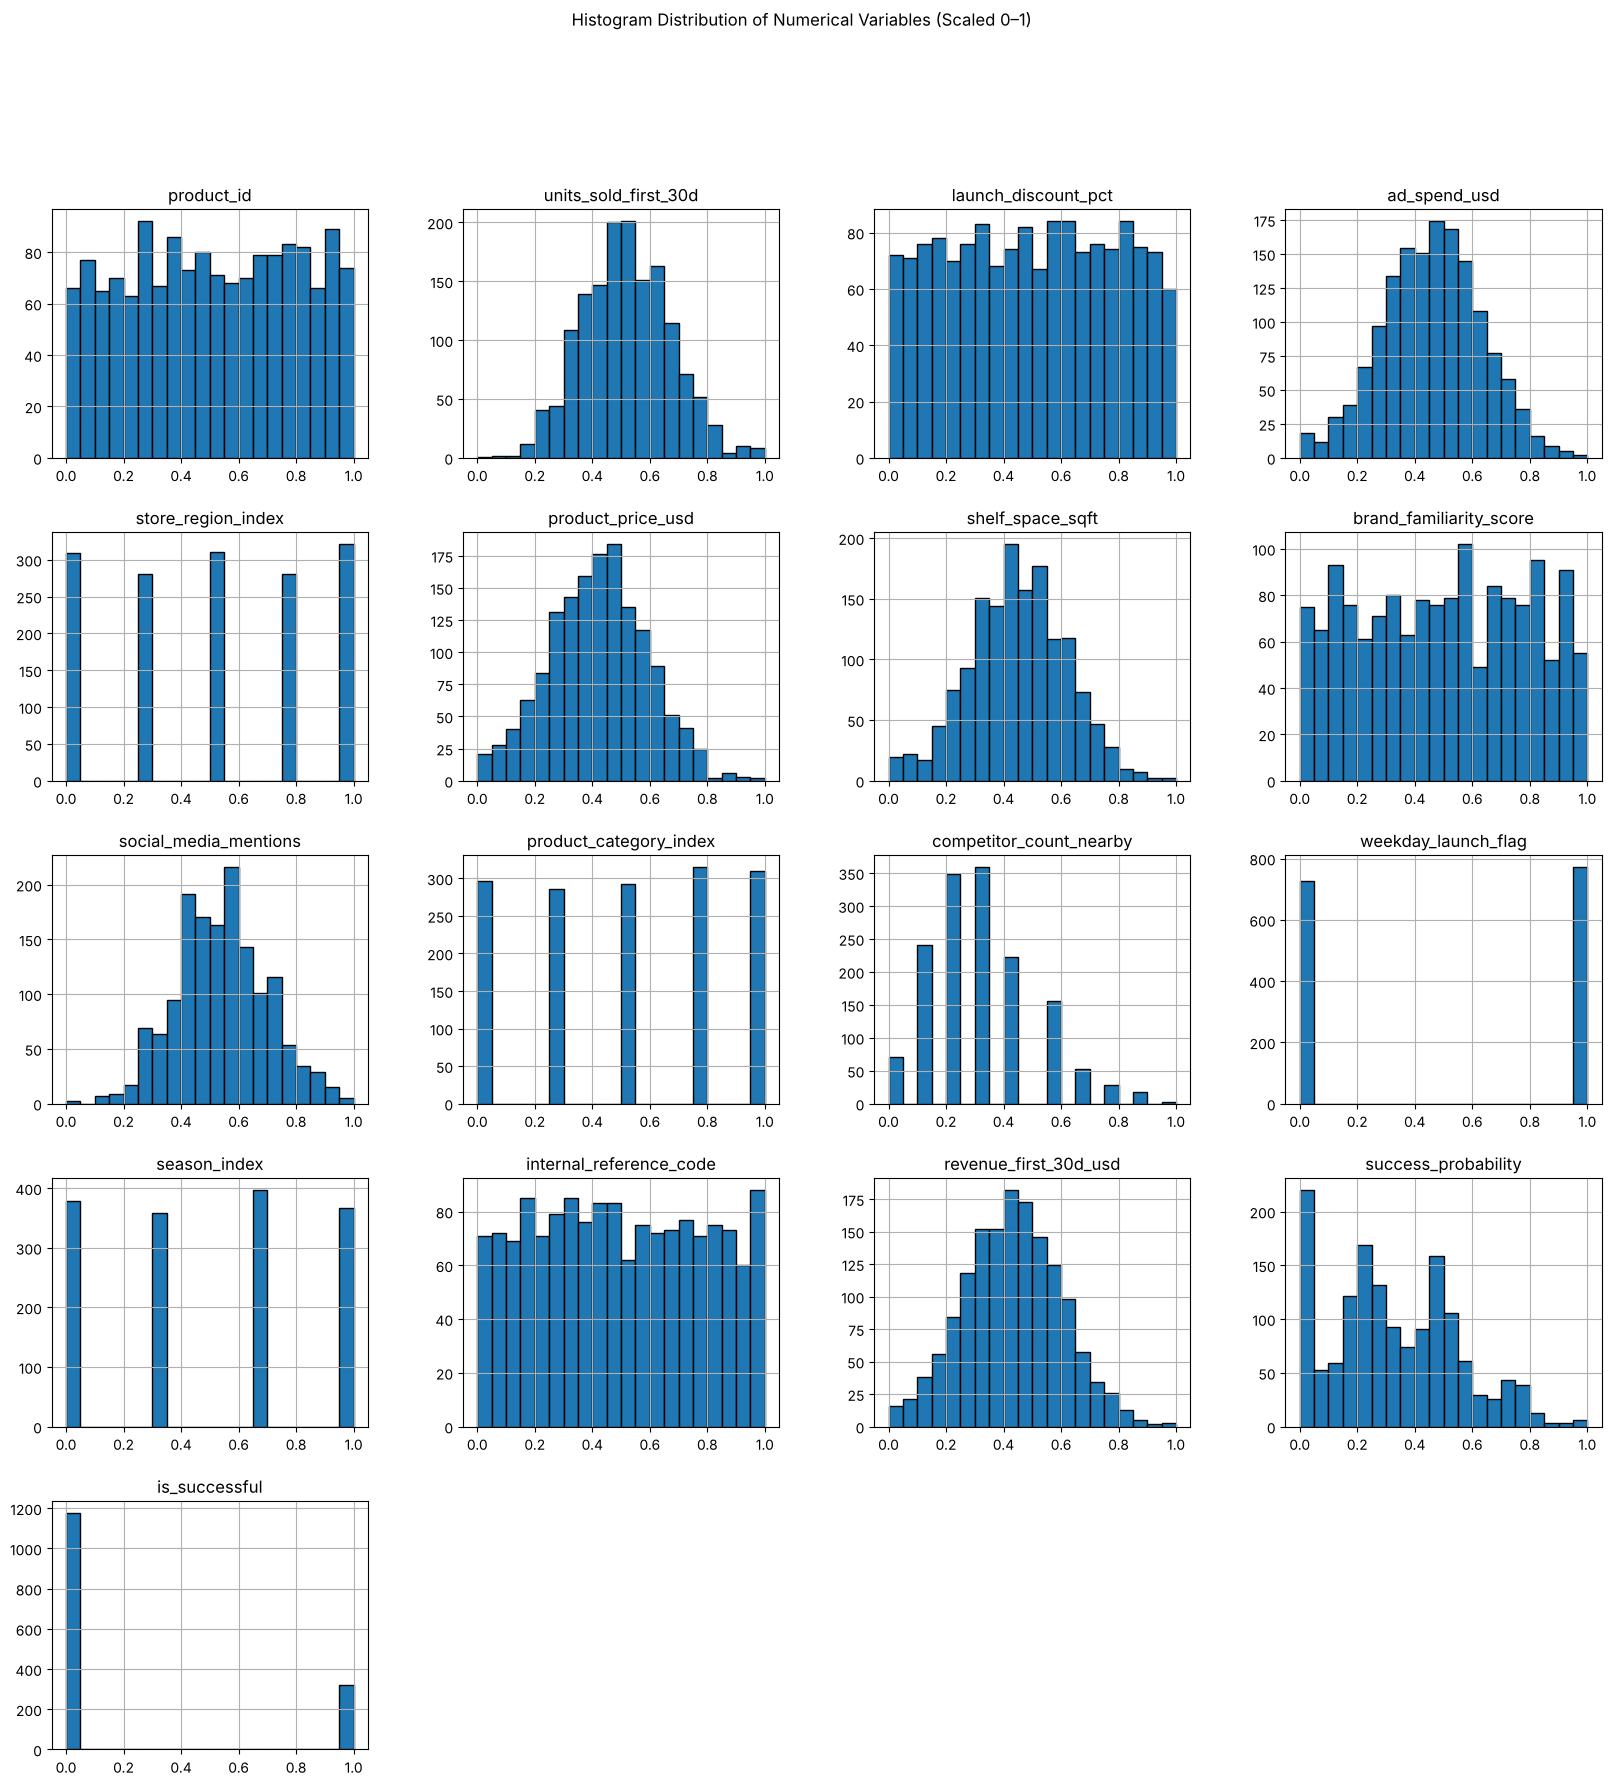

In [4]:
# Visualising dataset information
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df.select_dtypes(include=['float64', 'int64']))
scaled_df = pd.DataFrame(scaled_data, columns=df.select_dtypes(include=['float64', 'int64']).columns)
scaled_df.hist(figsize=(20, 20), bins=20, edgecolor='black')
plt.suptitle("Histogram Distribution of Numerical Variables (Scaled 0–1)", fontsize=12)
plt.show()

## Discussion

Based on the dataset, the chosen research question is: **"What factors are most predictive of a product's launch success probability?"** The selected dependent variable (DV) is **'success_probability'** since it directly reflects launch success on a 0 to 1 scale, making it suitable for conducting regression analysis.

The independent variables (IV) include:

1. **'brand_familiarity_score'** - since stronger brand recognition is expected to increase the likelihood of launch success.
2. **'ad_spend_usd'** - as high advertising investment can boost awareness and post-launch sales.
3. **'social_media_mentions'** - reflects public interest and potential demand of the product after launch.
4. **'launch_discount_pct'** - effectively encourages people to try out something new by lowering perceived risk.

Since each of these variables can influence product launches, it is suitable to use these variables for the analysis.

## Data Exploration

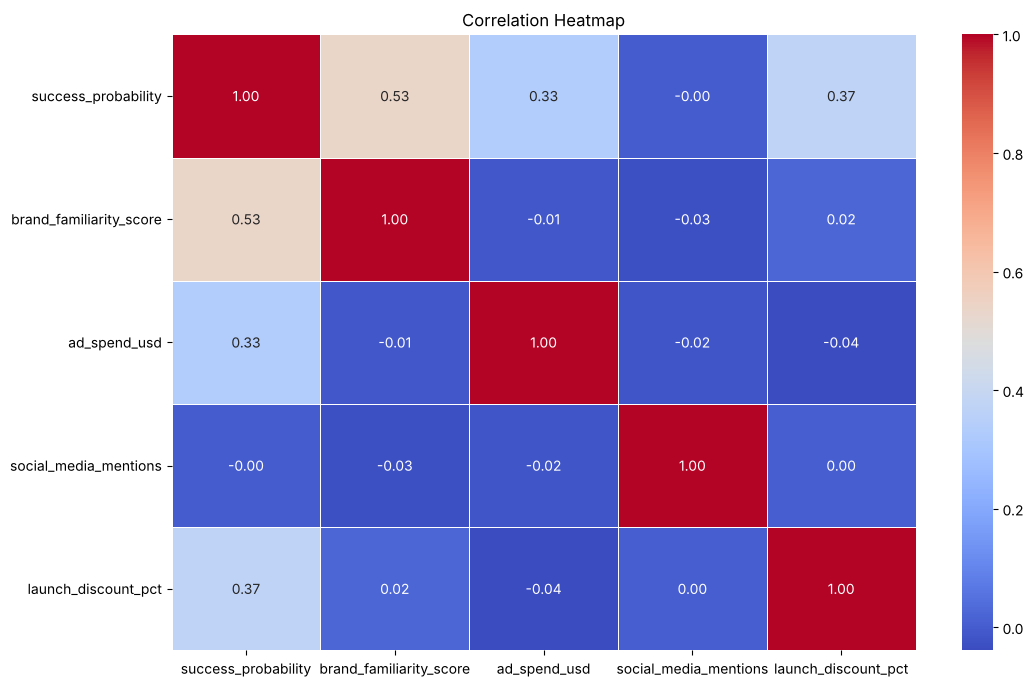

In [5]:
# Selecting only the chosen variables
df_model = df[['success_probability', 'brand_familiarity_score', 'ad_spend_usd',
               'social_media_mentions', 'launch_discount_pct']]

# Computing the correlation matrix
correlation_matrix = df_model.corr(numeric_only=True)

# Generating a heatmap to explore the correlation between variables
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.savefig("../figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Observations from Output

The heatmap shows that **brand_familiarity_score (0.53)** has the strongest correlation with **success_probability**, which is followed by **launch_discount_pct (0.37)** and **ad_spend_usd (0.33)**. Surprisingly, **social_media_mentions** show no relationship (-0.00), so it is left out of the simple models and tested once more in the multiple regression to confirm this.

## Analysis

### Simple Linear Regression 1: success_probability ~ brand_familiarity_score

In [6]:
# Testing the correlation between the variables
corr, p_value = stats.pearsonr(df['success_probability'], df['brand_familiarity_score'])
print(f"Correlation: {corr:.2f} (p-value: {p_value:.4f})")

Correlation: 0.53 (p-value: 0.0000)


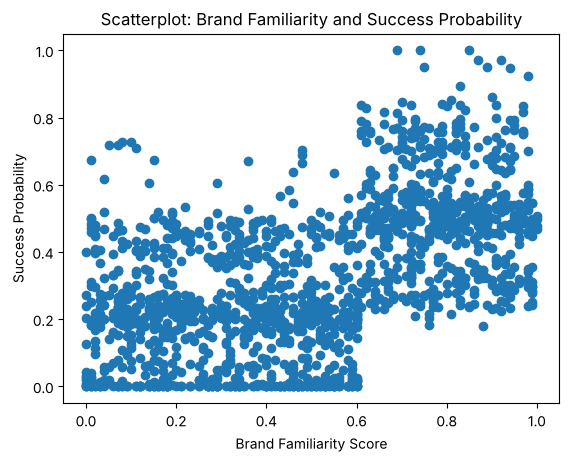

In [7]:
# Visualising the relationship with a scatterplot
plt.scatter(df['brand_familiarity_score'], df['success_probability'])
plt.title("Scatterplot: Brand Familiarity and Success Probability")
plt.xlabel("Brand Familiarity Score")
plt.ylabel("Success Probability")
plt.show()

In [8]:
# Building the linear regression model
X = sm.add_constant(df['brand_familiarity_score'])
y = df['success_probability']
model1 = sm.OLS(y, X).fit()

# Displaying regression summary
print(model1.summary())

                             OLS Regression Results                            
Dep. Variable:     success_probability   R-squared:                       0.286
Model:                             OLS   Adj. R-squared:                  0.285
Method:                  Least Squares   F-statistic:                     599.4
Date:                 Thu, 29 Oct 2026   Prob (F-statistic):          1.27e-111
Time:                         19:41:08   Log-Likelihood:                 386.40
No. Observations:                 1500   AIC:                            -768.8
Df Residuals:                     1498   BIC:                            -758.2
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const           

### Interpretation: Model 1

### 1. Model Overview
This model tests whether **brand_familiarity_score** can predict the probability of a successful product launch.

### 2. Regression Equation
**success_probability** = 0.1205 + 0.4133 × **brand_familiarity_score**

### 3. Key Results

| Metric | Value | Interpretation |
|---|---|---|
| Coefficient (brand familiarity) | **0.4133** | A 1-unit increase in familiarity raises success probability by **0.41** (41 percentage points), which is a strong practical effect on a 0–1 scale |
| p-value | **< 0.001** | Brand familiarity is a statistically significant predictor and this effect is unlikely due to random chance |
| R-squared | **0.286** | **28.6%** of success probability is explained by familiarity which is really high for a single variable model |
| Adjusted R-squared | **0.285** | Almost equal to R², which confirms the model is stable |

### 4. General Interpretation
Brand familiarity is a significant and strong predictor of launch success. The positive coefficient also indicates that products coming from a well-known brand are more likely to perform well at launch.

### Simple Linear Regression 2: success_probability ~ launch_discount_pct

In [9]:
# Testing the correlation between the variables
corr2, p_value2 = stats.pearsonr(df['success_probability'], df['launch_discount_pct'])
print(f"Correlation: {corr2:.2f} (p-value: {p_value2:.4f})")

Correlation: 0.37 (p-value: 0.0000)


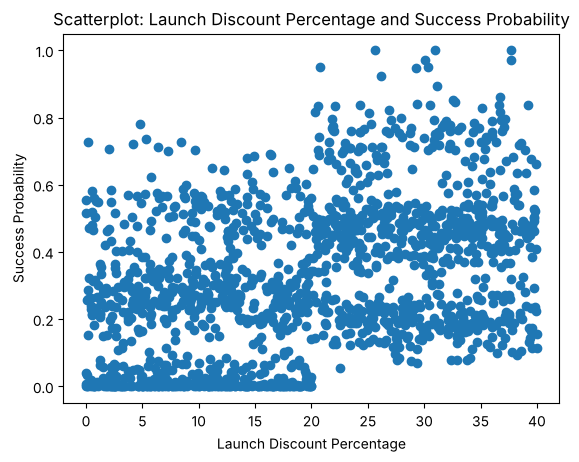

In [10]:
# Visualising the relationship with a scatterplot
plt.scatter(df['launch_discount_pct'], df['success_probability'])
plt.title("Scatterplot: Launch Discount Percentage and Success Probability")
plt.xlabel("Launch Discount Percentage")
plt.ylabel("Success Probability")
plt.show()

In [11]:
# Building the linear regression model
X2 = sm.add_constant(df['launch_discount_pct'])
y2 = df['success_probability']
model2 = sm.OLS(y2, X2).fit()

# Displaying regression summary
print(model2.summary())

                             OLS Regression Results                            
Dep. Variable:     success_probability   R-squared:                       0.140
Model:                             OLS   Adj. R-squared:                  0.139
Method:                  Least Squares   F-statistic:                     243.7
Date:                 Thu, 29 Oct 2026   Prob (F-statistic):           5.08e-51
Time:                         19:41:08   Log-Likelihood:                 247.03
No. Observations:                 1500   AIC:                            -490.1
Df Residuals:                     1498   BIC:                            -479.4
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   

### Interpretation: Model 2

### 1. Model Overview
This model tests whether **launch_discount_pct** predicts the probability of a successful product launch.

### 2. Regression Equation
**success_probability** = 0.1817 + 0.0073 × **launch_discount_pct**

### 3. Key Results

| Metric | Value | Interpretation |
|---|---|---|
| Coefficient (launch discount) | **0.0073** | A 1% increase in discount raises success probability by **0.0073** (0.73 percentage points), which is a small positive effect. |
| p-value | **< 0.001** | The discount level is statistically significant, meaning the effect is unlikely to be random |
| R-squared | **0.140** | **14%** of success probability is explained by discount alone, which is moderate but weaker than brand familiarity |
| Adjusted R-squared | **0.139** | Almost the same as R², so the single predictor is not inflating the fit |

### 4. General Interpretation
While offering a higher discount can increase success probability, the model explains only **14%** of the variation, meaning discounts alone do not strongly determine launch outcomes. But it should be utilised as a supporting tactic.

### Testing Assumptions: Model 1

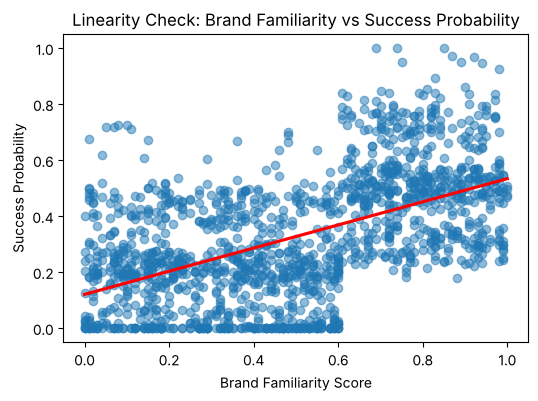

In [12]:
# ASSUMPTION 1: Linearity
plt.figure(figsize=(6,4))
sns.regplot(x=df['brand_familiarity_score'], y=df['success_probability'], ci=None, scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})
plt.title("Linearity Check: Brand Familiarity vs Success Probability")
plt.xlabel("Brand Familiarity Score")
plt.ylabel("Success Probability")
plt.savefig("../figures/linearity_brand_familiarity.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# ASSUMPTION 2: Independence of Errors
dw_stat_model1 = durbin_watson(model1.resid)
print(f"Durbin-Watson Statistic (Model 1): {dw_stat_model1:.2f}")

Durbin-Watson Statistic (Model 1): 1.97


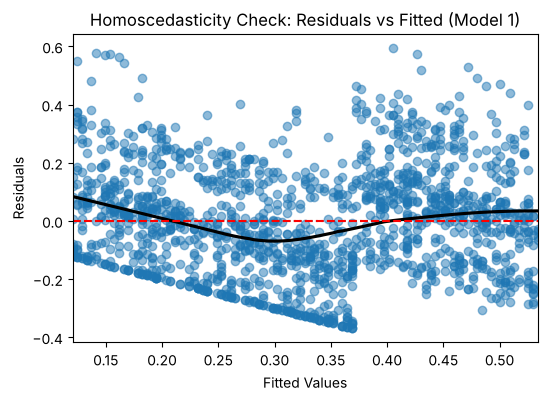

In [14]:
# ASSUMPTION 3: Homoscedasticity (Residuals vs Fitted Plot)
plt.figure(figsize=(6,4))
sns.residplot(x=model1.fittedvalues, y=model1.resid, lowess=True, scatter_kws={'alpha':0.5}, line_kws={'color': 'black'})
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Homoscedasticity Check: Residuals vs Fitted (Model 1)")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.savefig("../figures/residuals_vs_fitted_model1.png", dpi=150, bbox_inches="tight")
plt.show()

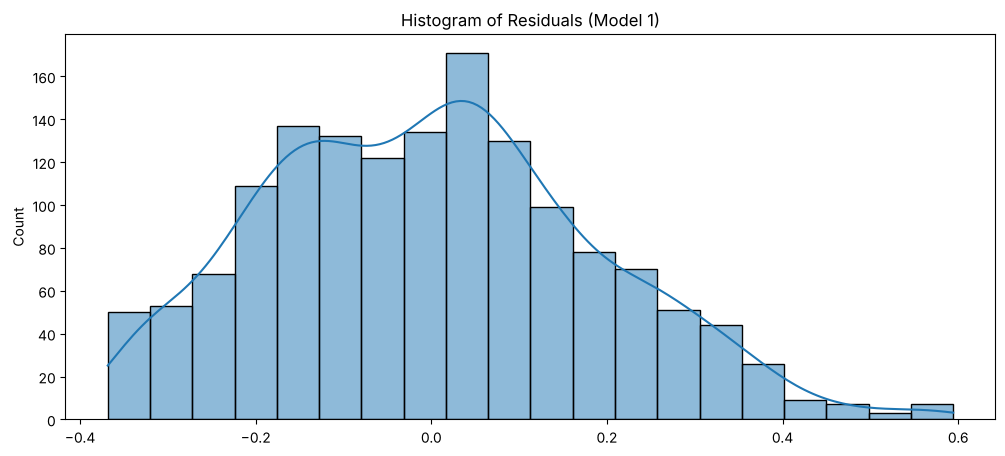

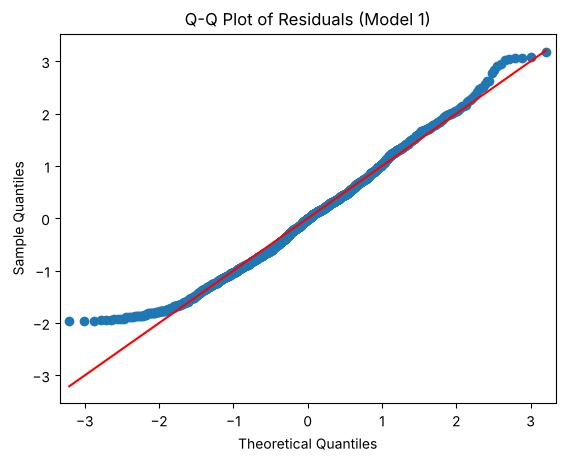

In [15]:
# ASSUMPTION 4: Normality of Residuals
plt.figure(figsize=(12,5))
sns.histplot(model1.resid, kde=True, bins=20)
plt.title("Histogram of Residuals (Model 1)")
plt.show()

plt.figure(figsize=(12,5))
sm.qqplot(model1.resid, line='s', fit = True)
plt.title("Q-Q Plot of Residuals (Model 1)")
plt.savefig("../figures/qq_plot_model1.png", dpi=150, bbox_inches="tight")
plt.show()

### Observation: Model 1
All four key regression assumptions were tested:

- **Linearity** - The scatterplot shows a clear positive trend, but it looks more like a step at a familiarity score of about 0.6 than a straight line, so the linear model is an approximation.
- **Independence of Errors** - The Durbin–Watson statistic was **1.97**, which is very close to **2**, indicating no autocorrelation in residuals.
- **Homoscedasticity** - There is no funnel shape, so the variance looks broadly constant, but a straight lower band appears because many launches have a success probability of exactly 0.
- **Normality of Residuals** - The histogram and Q-Q plot show a clearly short lower tail, caused by the floor at 0. With 1,500 launches this matters less for the coefficients.

Overall, independence and constant variance hold reasonably well, but the step at about 0.6 and the floor at 0 mean Model 1 is a useful approximation rather than a perfect fit.

### Testing Assumptions: Model 2

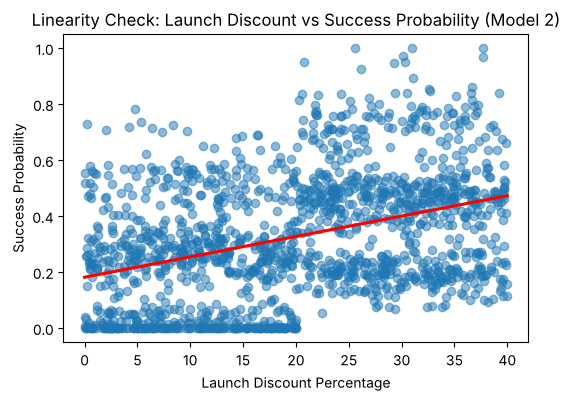

In [16]:
# ASSUMPTION 1: Linearity
plt.figure(figsize=(6,4))
sns.regplot(x=df['launch_discount_pct'], y=df['success_probability'], ci=None, scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})
plt.title("Linearity Check: Launch Discount vs Success Probability (Model 2)")
plt.xlabel("Launch Discount Percentage")
plt.ylabel("Success Probability")
plt.show()

In [17]:
# ASSUMPTION 2: Independence of Errors
dw_stat_model2 = durbin_watson(model2.resid)
print(f"Durbin-Watson Statistic (Model 2): {dw_stat_model2:.2f}")

Durbin-Watson Statistic (Model 2): 1.96


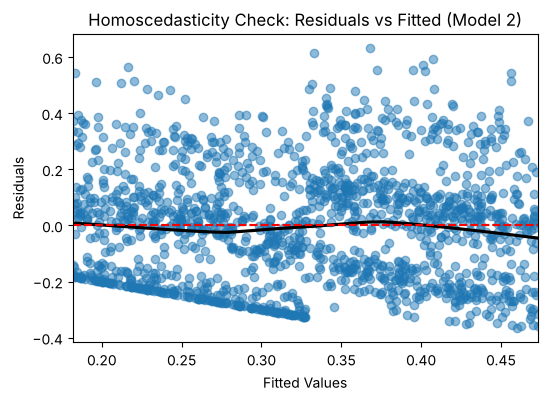

In [18]:
# ASSUMPTION 3: Homoscedasticity (Residuals vs Fitted Plot)
plt.figure(figsize=(6,4))
sns.residplot(x=model2.fittedvalues, y=model2.resid, lowess=True, scatter_kws={'alpha':0.5}, line_kws={'color': 'black'})
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Homoscedasticity Check: Residuals vs Fitted (Model 2)")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

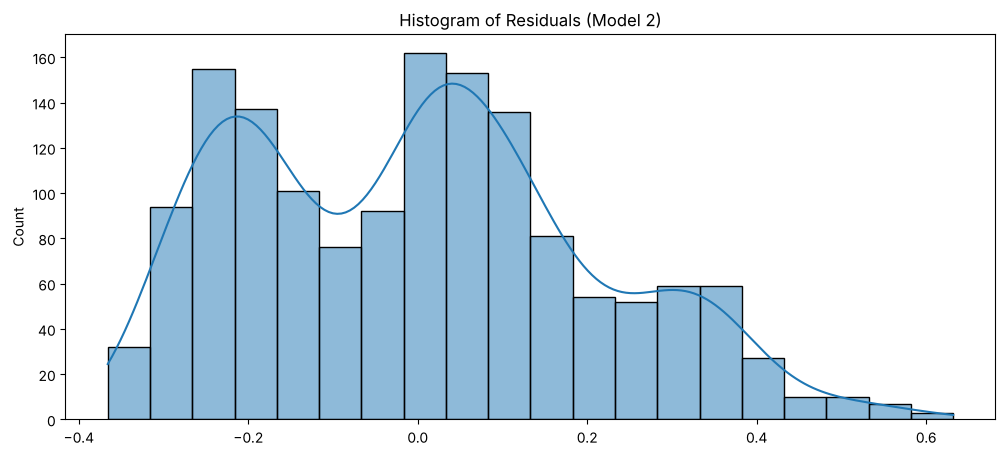

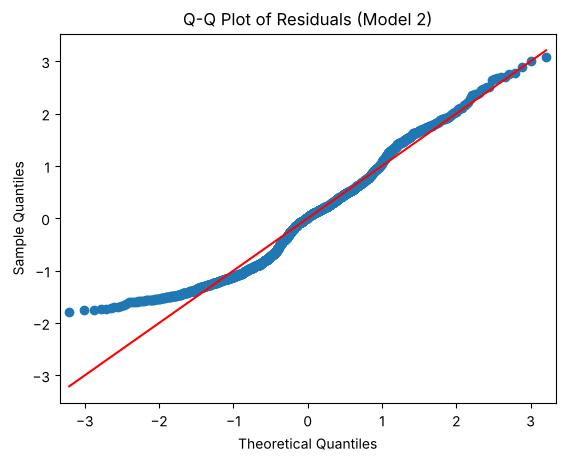

In [19]:
# ASSUMPTION 4: Normality of Residuals
plt.figure(figsize=(12,5))
sns.histplot(model2.resid, kde=True, bins=20)
plt.title("Histogram of Residuals (Model 2)")
plt.show()

plt.figure(figsize=(12,5))
sm.qqplot(model2.resid, line='s', fit=True)
plt.title("Q-Q Plot of Residuals (Model 2)")
plt.show()

### Observation: Model 2
All four key assumptions of simple linear regression were tested:

- **Linearity** - The relationship remained positive, but weaker than in **Model 1**. Which means the model is appropriate but the effect is not very strong.
- **Independence of Errors** - Durbin–Watson statistic value of **1.96** again indicates no autocorrelation.
- **Homoscedasticity** - Residuals show no clear funnel shape, although the same lower band from the floor at 0 appears.
- **Normality of Residuals** - The histogram and Q-Q plot show deviations from normality in the lower tail, which are less of a concern with a sample this large.

Overall, the assumptions hold well enough for a simple model, and the weaker trend suggests that launch discounts are less influential than brand familiarity.

### Multiple Linear Regression: Model 1

Beginning with **brand_familiarity_score** and **launch_discount_pct**, as these showed the strongest individual relationships with **success_probability** in the earlier analysis.

In [20]:
# MLR Model 1: Baseline model with 2 predictors
model_mlr1 = ols("success_probability ~ brand_familiarity_score + launch_discount_pct", data=df).fit()
print("OLS Regression Model 1: Baseline Predictors (Brand Familiarity + Launch Discount)")
print(model_mlr1.summary())

OLS Regression Model 1: Baseline Predictors (Brand Familiarity + Launch Discount)
                             OLS Regression Results                            
Dep. Variable:     success_probability   R-squared:                       0.416
Model:                             OLS   Adj. R-squared:                  0.416
Method:                  Least Squares   F-statistic:                     534.1
Date:                 Thu, 29 Oct 2026   Prob (F-statistic):          8.26e-176
Time:                         19:41:10   Log-Likelihood:                 537.92
No. Observations:                 1500   AIC:                            -1070.
Df Residuals:                     1497   BIC:                            -1054.
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
--------------------------

### Interpretation: Model 1

### Predictor Analysis

- **Brand Familiarity Score** (Coefficient = 0.4066, p < 0.001): A one-unit increase in brand familiarity is associated with an increase of 0.41 in success probability. The effect is highly significant (p < 0.001) and it confirms that brand familiarity is a major driver of launch success.

- **Launch Discount Percentage** (Coefficient = 0.0070, p < 0.001): A 1% increase in launch discount is associated with a 0.007 increase in success probability. Although the effect is statistically significant (p < 0.001), the small effect size means discounts provide a modest tactical boost rather than being a primary driver.

### Model Fit

- **R-squared = 0.416 / Adjusted R-squared = 0.416:** This means that 41.6% of the variation in success probability is explained by these two predictors. This is a strong result for a 2-predictor model, indicating both variables are meaningful contributors.

### Assumptions

- **Skew (0.362) & Kurtosis (2.678):** Residuals show mild skewness but are still within the acceptable range for linear regression.

- **Durbin–Watson = 1.983:** Very close to 2, indicating no autocorrelation in residuals.

### Key Takeaway
Brand familiarity plays a dominant role in determining launch success, while launch discount has a smaller but statistically reliable effect.

### Model 2: Adding Social Media Mentions

**social_media_mentions** is added to the model because this variable represents the level of public attention and online discussion during launch week, which can strongly influence consumer interest.

In [21]:
# MLR Model 2: Adding social media mentions as third predictor
model_mlr2 = ols("success_probability ~ brand_familiarity_score + launch_discount_pct + social_media_mentions", data=df).fit()
print("\nOLS Regression Model 2: Adding Social Media Mentions")
print(model_mlr2.summary())


OLS Regression Model 2: Adding Social Media Mentions
                             OLS Regression Results                            
Dep. Variable:     success_probability   R-squared:                       0.417
Model:                             OLS   Adj. R-squared:                  0.415
Method:                  Least Squares   F-statistic:                     356.1
Date:                 Thu, 29 Oct 2026   Prob (F-statistic):          1.77e-174
Time:                         19:41:10   Log-Likelihood:                 538.12
No. Observations:                 1500   AIC:                            -1068.
Df Residuals:                     1496   BIC:                            -1047.
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

### Interpretation: Model 2
Including **social_media_mentions** does not meaningfully improve the model, as the R-squared increases only slightly from 0.416 to 0.417. The variable is statistically insignificant (p = 0.531), indicating that social media activity does not add predictive value once brand familiarity and launch discount are already included.

### Model 3: Adding Advertising Spend

Since **social_media_mentions** did not improve the model, it was excluded and replaced by **ad_spend_usd** as it represents a controllable strategic factor during launch campaigns.

In [22]:
# Model 3: Adding Advertising Spend
model_mlr3 = ols("success_probability ~ brand_familiarity_score + launch_discount_pct + ad_spend_usd", data=df).fit()
print("\nOLS Regression Model 3: Adding Advertising Spend")
print(model_mlr3.summary())


OLS Regression Model 3: Adding Advertising Spend
                             OLS Regression Results                            
Dep. Variable:     success_probability   R-squared:                       0.541
Model:                             OLS   Adj. R-squared:                  0.540
Method:                  Least Squares   F-statistic:                     586.6
Date:                 Thu, 29 Oct 2026   Prob (F-statistic):          5.43e-252
Time:                         19:41:10   Log-Likelihood:                 717.21
No. Observations:                 1500   AIC:                            -1426.
Df Residuals:                     1496   BIC:                            -1405.
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

### Interpretation: Model 3
Adding **ad_spend_usd** to the model resulted in a clear improvement, with R-squared increasing from **0.417** to **0.541**, meaning the model now explains **54.1%** of the variation in **success_probability**. All three predictors remain statistically significant **(p < 0.001)**, and the adjusted R-squared **(0.540)** also confirms that the added variable meaningfully improves model fit.

### Comparing Models

In [23]:
#Comparing the models
print("\nModel Comparisons:")
print(f"Model 1 R-squared: {model_mlr1.rsquared:.4f}, AIC: {model_mlr1.aic:.2f}")
print(f"Model 2 R-squared: {model_mlr2.rsquared:.4f}, AIC: {model_mlr2.aic:.2f}")
print(f"Model 3 R-squared: {model_mlr3.rsquared:.4f}, AIC: {model_mlr3.aic:.2f}")


Model Comparisons:
Model 1 R-squared: 0.4164, AIC: -1069.85
Model 2 R-squared: 0.4166, AIC: -1068.24
Model 3 R-squared: 0.5405, AIC: -1426.42


### Interpretation

- **Model 3** has the highest R-squared **(0.5405)** and lowest **AIC**, indicating the strongest and most efficient overall fit which offers the best balance between accuracy and model complexity.
- Adding **ad_spend_usd** in **Model 3** led to a major improvement in performance, showing that advertising investment is an important predictor of launch success.
- **Model 2** underperforms, proving social media mentions add no predictive value beyond brand familiarity and discounts.
- All variables in **Model 3** are both statistically significant and logically justified, reflecting realistic business factors such as brand recognition, price incentive, and marketing spend.

# Conclusion

### Key Findings

**Brand familiarity** is the strongest predictor of product launch success, with the highest positive impact on success probability. **Launch discounts** also contribute positively, although their effect is smaller and more tactical in nature. The inclusion of **advertising spend** in **Model 3** significantly improved model performance **(R² = 0.5405)**, showing that media investment is strongly associated with successful launches. In contrast, **social media mentions** had no predictive value, indicating that online engagement alone does not translate into launch success.

Overall, Model 3 delivered the best fit, with the highest R² and lowest AIC. All included variables were statistically significant and aligned with realistic business logic. The assumption checks were carried out on the simple models only. The model remains valid despite the large condition number, which is likely due to the high scale of ad spend rather than multicollinearity.

### Business Recommendations

1. **Invest in brand familiarity before launch, not during it:**

- Build pre-launch brand equity through promotional campaigns, brand storytelling, influencer associations.
- Treat launch as the conversion phase rather than seeing it as an awareness phase.
- For newer brands, build reputation before taking pricing or promotional decisions.

2. **Use launch discounts strategically:**

- Use dynamic discounting such as pre-order, early-bird, loyalty-based tiers instead of flat discounts.
- For unpopular brands, discounts should be paired with credibility signals to build brand image.

3. **Optimise advertising budget based on brand familiarity:**

- For high-familiarity brands, the advertisement budget should focus on amplifying the pre-established strong perception.
- For low-familiarity brands, advertisement spend should prioritise building credibility and trust.
- For all products, media investment should be treated as essential, not optional.

4. **Re-evaluate the role of social media:**

- Instead of using social media mentions as a metric of launch success, use social media as a mechanism to build brand image and familiarity.

In essence, launch success is not a function of how loudly a product enters the market, but how strongly the brand is established before it arrives.